# Análisis de reseñas de apps bancarias peruanas con PLN

Este proyecto trabaja con reseñas públicas de Google Play de cinco apps bancarias que se usan en el Perú: Yape, BCP, Interbank, BBVA y Scotiabank. Las reseñas se descargaron con la librería google-play-scraper de Python. Se pidieron las 4 000 más recientes de cada app, en español y para Perú, y después de la limpieza quedaron 20 000 reseñas.

Cada reseña trae el texto que escribió el usuario, la calificación de 1 a 5 estrellas, la fecha, la versión de la app, cuántas personas la marcaron como útil y, si la hubo, la respuesta del banco. No se guardaron el nombre ni la foto de los usuarios. Las estrellas sirven como etiqueta de sentimiento (1 y 2 negativo, 3 neutro, 4 y 5 positivo), por eso no hizo falta etiquetar las reseñas a mano.

Con estos datos se buscó saber qué tan satisfechos están los usuarios, de qué se quejan y en qué se diferencia cada banco. Al final del notebook se guardan los modelos que usa la app de Streamlit (`app.py`).

| Fase | Qué se hace |
|---|---|
| 1. Recolección | Descarga de reseñas públicas de Yape, BCP, Interbank, BBVA y Scotiabank |
| 2. Limpieza de la base | Vacíos, duplicados y etiqueta de sentimiento según las estrellas |
| 3. Exploración | Distribución de estrellas, longitud y fechas de las reseñas |
| 4. Preprocesamiento | Limpieza con regex, emojis, jerga, tokenización, stopwords, lematización y stemming |
| 5. Técnicas de PLN | TF-IDF, sentimiento, tipo de reclamo, temas (LDA), similitud (LSA) y extracción de información |
| 6. Análisis | Comparación entre bancos |
| 7. Exportación | Modelos y datos para la app |

## 0. Configuración del entorno

In [ ]:
import os, json, warnings
from collections import Counter
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             f1_score, accuracy_score)
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.preprocessing import normalize

from src.recoleccion import APPS, recolectar
from src.pln_utils import (cargar_spacy, pasos_preprocesamiento, preprocesar_lote,
                           sentimiento_por_estrellas, clasificar_reclamo, CATEGORIAS,
                           SIN_CATEGORIA, extraer_informacion, buscar_similares,
                           STOP_DOMINIO, preparar_para_ner, entidades_ner)
from src.estilo import COLORES_APP, COLORES_SENT, ORDEN_SENT, estilo_matplotlib

warnings.filterwarnings("ignore")
estilo_matplotlib()
pd.set_option("display.max_colwidth", 140)
SEMILLA = 42
for carpeta in ["data/raw", "data/processed", "models"]:
    os.makedirs(carpeta, exist_ok=True)

nlp = cargar_spacy()   # modelo es_core_news_sm de spaCy


def color_texto(v, valores):
    # texto blanco sobre celdas oscuras y negro sobre celdas claras (mapas de calor)
    lo, hi = np.nanmin(valores), np.nanmax(valores)
    return "white" if hi > lo and (v - lo) / (hi - lo) > 0.55 else "#0b0b0b"

## 1. Recolección de datos

**Fuente:** reseñas públicas de Google Play, descargadas con la librería `google-play-scraper`. Se piden las reseñas más recientes en español y para Perú (`lang="es"`, `country="pe"`).

| App | Id en Google Play |
|---|---|
| Yape | com.bcp.innovacxion.yapeapp |
| BCP (Banca Móvil) | com.bcp.bank.bcp |
| Interbank | pe.com.interbank.mobilebanking |
| BBVA Perú | com.bbva.nxt_peru |
| Scotiabank Perú | pe.com.scotiabank.blpm.android.client |

Si el archivo `data/raw/resenas_raw.csv` ya existe, se carga y no se vuelve a descargar. Así los resultados no cambian cada vez que se ejecuta el notebook.

In [3]:
RUTA_RAW = "data/raw/resenas_raw.csv"
N_POR_APP = 4000   # reseñas más recientes por app

if os.path.exists(RUTA_RAW):
    raw = pd.read_csv(RUTA_RAW)
    print("Se cargó el archivo guardado:", RUTA_RAW)
else:
    raw = recolectar(APPS, n=N_POR_APP)
    raw.to_csv(RUTA_RAW, index=False, encoding="utf-8")
    print("Reseñas descargadas y guardadas en", RUTA_RAW)

print(f"Total: {len(raw):,} reseñas")
raw.head()

Yape: 4,000 reseñas


BCP: 4,000 reseñas


Interbank: 4,000 reseñas


BBVA: 4,000 reseñas


Scotiabank: 4,000 reseñas


Reseñas descargadas y guardadas en data/raw/resenas_raw.csv
Total: 20,000 reseñas


,reviewId,app,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt
0,28eb97fa-982f-4fda-b2c6-31e38fdcf1c1,Yape,"que está pasando con yape desde su actualización, no me deja entrar a promos ni entradas",1,0,3.70.0,2026-11-14 21:14:01,NaN,NaT
1,7b9f868e-d8d2-4c95-b9f4-9d48d8a6b5d1,Yape,buena aplicación,5,0,NaN,2026-11-14 21:09:30,NaN,NaT
2,2034e9e9-444d-46e4-b331-d0e074c8c54e,Yape,es bueno y fácil de pagar.,5,0,NaN,2026-11-14 21:01:33,NaN,NaT
3,35150402-7e97-4d08-b880-16e4a7aff9f4,Yape,muy malo cada dia peor,5,0,3.70.0,2026-11-14 20:53:50,NaN,NaT
4,7e38fdb0-da3d-408d-ba3e-41cd8729e098,Yape,"el app se actualizó y ya no me sale la interfaz como antes, no puedo pedir un crédito por esto, no sale el icono.",1,0,3.70.0,2026-11-14 20:15:47,NaN,NaT


## 2. Limpieza de la base y etiqueta de sentimiento

Antes de trabajar con el texto se revisa la base:

1. Se quitan las reseñas vacías.
2. Se quitan los duplicados por `reviewId`. No se quitan textos repetidos de usuarios distintos, porque reseñas cortas como "Excelente" son legítimas aunque se repitan.
3. Se crea la etiqueta de sentimiento a partir de las estrellas: 1 y 2 = **negativo**, 3 = **neutro**, 4 y 5 = **positivo**. Esta etiqueta sirve para entrenar y evaluar el clasificador sin etiquetar a mano.

In [4]:
df = raw.copy()
n_inicial = len(df)
df["content"] = df["content"].fillna("").astype(str).str.strip()
vacias = (df["content"] == "").sum()
df = df[df["content"] != ""]
duplicadas = df.duplicated("reviewId").sum()
df = df.drop_duplicates("reviewId").reset_index(drop=True)

df["fecha"] = pd.to_datetime(df["at"])
df["respondida"] = df["replyContent"].notna()
df["n_palabras"] = df["content"].str.split().str.len()
df["sentimiento"] = df["score"].apply(sentimiento_por_estrellas)
apps = [a for a in APPS if a in df["app"].unique()]

pd.DataFrame({
    "paso": ["Reseñas descargadas", "Vacías eliminadas", "Duplicadas eliminadas", "Reseñas finales"],
    "cantidad": [n_inicial, vacias, duplicadas, len(df)],
})

,paso,cantidad
0,Reseñas descargadas,20000
1,Vacías eliminadas,0
2,Duplicadas eliminadas,0
3,Reseñas finales,20000


## 3. Análisis exploratorio

Primero se ve cuántas reseñas hay por app, el promedio de estrellas y qué periodo cubre cada una. Como se descargan las reseñas más recientes, una app con muchos usuarios (como Yape) llena su cuota en pocos días, mientras que otra puede cubrir varios meses. Esto se toma en cuenta al comparar fechas.

In [5]:
resumen = df.groupby("app").agg(
    reseñas=("reviewId", "size"),
    estrellas_promedio=("score", "mean"),
    pct_negativas=("sentimiento", lambda s: (s == "negativo").mean() * 100),
    pct_respondidas=("respondida", lambda s: s.mean() * 100),
    desde=("fecha", "min"),
    hasta=("fecha", "max"),
).reindex(apps)
resumen["dias_cubiertos"] = (resumen["hasta"] - resumen["desde"]).dt.days
resumen["desde"] = resumen["desde"].dt.date
resumen["hasta"] = resumen["hasta"].dt.date
resumen.round(1)

,reseñas,estrellas_promedio,pct_negativas,pct_respondidas,desde,hasta,dias_cubiertos
app,,,,,,,
Yape,4000,3.6,31.8,95.4,2026-09-21,2026-11-14,54
BCP,4000,3.6,30.8,37.8,2026-05-27,2026-11-14,171
Interbank,4000,2.7,54.5,0.0,2026-03-20,2026-11-14,239
BBVA,4000,3.1,45.0,80.7,2026-06-01,2026-11-14,166
Scotiabank,4000,1.8,79.6,0.4,2025-02-22,2026-11-14,630


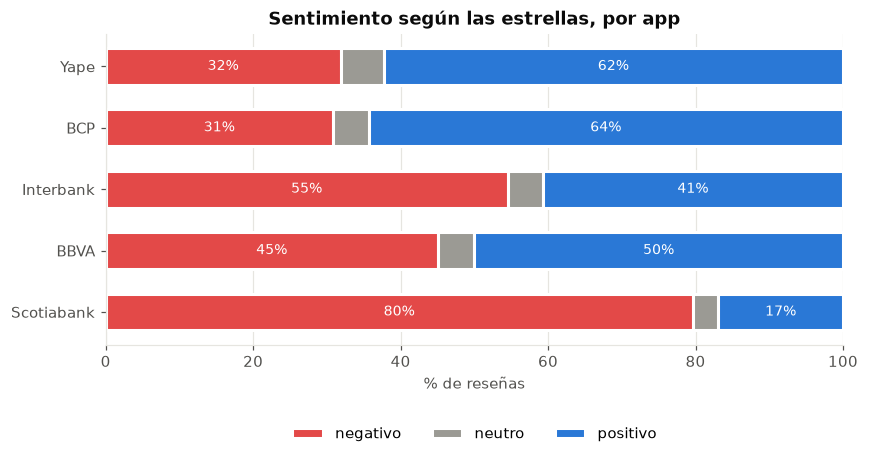

In [6]:
prop = (pd.crosstab(df["app"], df["sentimiento"], normalize="index")
          .reindex(index=apps, columns=ORDEN_SENT).fillna(0) * 100)

fig, ax = plt.subplots(figsize=(8, 0.6 * len(apps) + 1.4))
izquierda = np.zeros(len(prop))
for s in ORDEN_SENT:
    ax.barh(prop.index, prop[s], left=izquierda, color=COLORES_SENT[s], label=s,
            height=0.6, edgecolor="white", linewidth=2)
    for i, (v, l) in enumerate(zip(prop[s], izquierda)):
        if v >= 7:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    izquierda += prop[s].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% de reseñas")
ax.set_title("Sentimiento según las estrellas, por app")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.show()

In [7]:
# Longitud de las reseñas: las negativas suelen ser más largas porque explican el problema
df.groupby("sentimiento")["n_palabras"].describe()[["count", "mean", "50%", "max"]] \
  .reindex(ORDEN_SENT).round(1).rename(columns={"50%": "mediana"})

,count,mean,mediana,max
sentimiento,,,,
negativo,9671.0,20.9,16.0,105.0
neutro,956.0,16.6,10.0,95.0
positivo,9373.0,5.2,2.0,107.0


> **Interpretación:** [completar con los resultados: qué app tiene más reseñas negativas, si las negativas son más largas, qué periodo cubre cada app]

## 4. Preprocesamiento del texto

Las reseñas tienen mayúsculas, emojis, signos repetidos ("!!!"), letras alargadas ("buenooo"), risas, jerga ("xq", "q", "pe") y abreviaturas ("app", "cel"). El preprocesamiento busca que palabras que significan lo mismo se escriban igual.

| Paso | Qué hace | Ejemplo |
|---|---|---|
| Limpieza con regex | Quita URLs, correos, menciones, números y signos | `"https://..."` → `""` |
| Emojis | Convierte cada emoji en un token, porque expresan sentimiento | 😡 → `emoji_cara_cabreada` |
| Alargamientos y risas | Reduce letras repetidas y une las risas en un token | `buenooo` → `bueno`, `jajaja` → `risa` |
| Minúsculas | Unifica mayúsculas y minúsculas | `Yape` → `yape` |
| Tokenización | Separa el texto en palabras | `"no carga"` → `["no", "carga"]` |
| Normalización de jerga | Corrige abreviaturas frecuentes | `xq` → `porque`, `app` → `aplicación` |
| Stopwords | Quita palabras muy frecuentes sin contenido | `el`, `de`, `que` |
| Lematización (spaCy) | Lleva cada palabra a su forma base | `cobraron` → `cobrar` |
| Stemming (Snowball) | Corta la palabra a su raíz | `transferencias` → `transferent` |
| Quitar tildes | Unifica `aplicación` y `aplicacion` (se conserva la ñ) | `rápido` → `rapido` |

Un detalle importante: la lista de stopwords de spaCy incluye palabras como "no", "nunca", "bien", "mal" y "mejor". Si se quitan, "no funciona" y "funciona" quedan iguales. Por eso se sacaron de la lista.

Abajo se muestran los pasos en tres reseñas reales.

In [8]:
import re
patron_ruido = re.compile(r"[\U0001F300-\U0001FAFF]|\bxq\b|\bq\b|!!")
con_ruido = df[df["content"].apply(lambda t: bool(patron_ruido.search(t)))]
fuente = con_ruido if len(con_ruido) >= 3 else df
for texto in fuente.sample(3, random_state=SEMILLA)["content"]:
    for paso, valor in pasos_preprocesamiento(texto, nlp).items():
        print(f"{paso}:\n   {valor}")
    print("-" * 100)

1. Texto original:
   Buenos días no me sale la opción crédito porque no es compatible con mi móvil, salía hace 2 meses pude acceder al crédito, pague a tiempo y ahora no sale la. opción, consulto y dice que tengo q tener un móvil más moderno, quiere decir que el beneficio implica y me obliga a comprar un nuevo equipo? solucionen eso por favor gracias, hoy 16 octubre 2026 sin solucion
2. Limpieza (regex, emojis, minúsculas):
   buenos días no me sale la opción crédito porque no es compatible con mi móvil salía hace meses pude acceder al crédito pague a tiempo y ahora no sale la opción consulto y dice que tengo q tener un móvil más moderno quiere decir que el beneficio implica y me obliga a comprar un nuevo equipo solucionen eso por favor gracias hoy octubre sin solucion
3. Tokenización:
   ['buenos', 'días', 'no', 'me', 'sale', 'la', 'opción', 'crédito', 'porque', 'no', 'es', 'compatible', 'con', 'mi', 'móvil', 'salía', 'hace', 'meses', 'pude', 'acceder', 'al', 'crédito', 'pague', 'a',

Se preparan cuatro versiones del texto para comparar después cuál funciona mejor en el clasificador:

- `texto_original`: solo minúsculas (línea base, sin preprocesar).
- `texto_limpio`: limpieza, jerga y stopwords.
- `texto_stem`: lo anterior más stemming.
- `texto_lema`: lo anterior con lematización en lugar de stemming.

Además, `texto_tema` es la versión lematizada sin los nombres de los bancos ni la palabra "aplicación". Se usa en el modelado de temas y en la similitud, porque esas palabras aparecen en casi todas las reseñas y no ayudan a separar temas.

In [9]:
%%time
textos = df["content"].tolist()
df["texto_original"] = preprocesar_lote(textos, modo="original")
df["texto_limpio"] = preprocesar_lote(textos, modo="limpio")
df["texto_stem"] = preprocesar_lote(textos, modo="stem")
df["texto_lema"] = preprocesar_lote(textos, modo="lema", nlp=nlp)
df["texto_tema"] = df["texto_lema"].apply(
    lambda s: " ".join(t for t in s.split() if t not in STOP_DOMINIO))

# Reseñas que quedaron vacías (por ejemplo, solo "ok" o solo signos) no sirven para modelar
df_modelo = df[df["texto_lema"].str.len() > 0].reset_index(drop=True)
print(f"Reseñas para modelar: {len(df_modelo):,} de {len(df):,}")

Reseñas para modelar: 19,946 de 20,000
CPU times: total: 49.3 s
Wall time: 51.5 s


In [10]:
def resumen_vocabulario(serie):
    tokens = serie.str.split()
    vocab = Counter(t for lista in tokens for t in lista)
    return pd.Series({"palabras distintas": len(vocab), "tokens por reseña": tokens.str.len().mean()})

pd.DataFrame({
    "Sin preprocesar": resumen_vocabulario(df_modelo["texto_original"]),
    "Limpieza + stopwords": resumen_vocabulario(df_modelo["texto_limpio"]),
    "Stemming": resumen_vocabulario(df_modelo["texto_stem"]),
    "Lematización": resumen_vocabulario(df_modelo["texto_lema"]),
}).T.round(1)

,palabras distintas,tokens por reseña
Sin preprocesar,17262.0,13.4
Limpieza + stopwords,10003.0,6.5
Stemming,5685.0,6.5
Lematización,7681.0,6.4


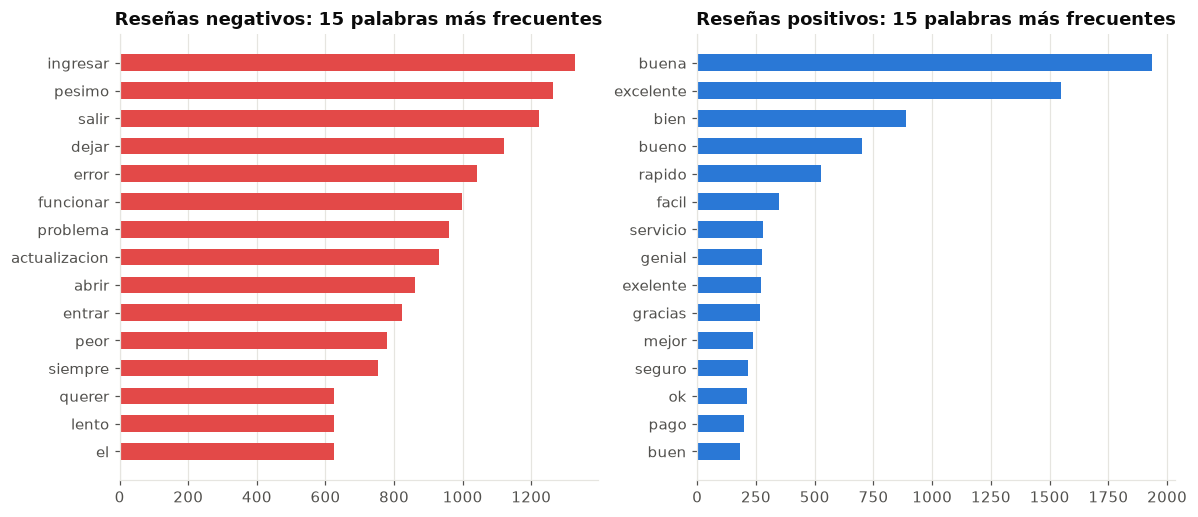

In [11]:
# Palabras más frecuentes en reseñas negativas y positivas (texto lematizado)
excluir = {"no", "ni", "nada", "sin"} | STOP_DOMINIO
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, s in zip(axes, ["negativo", "positivo"]):
    conteo = Counter(t for txt in df_modelo.loc[df_modelo["sentimiento"] == s, "texto_lema"]
                     for t in txt.split() if t not in excluir and not t.startswith("emoji_"))
    palabras, frec = zip(*conteo.most_common(15))
    ax.barh(palabras[::-1], frec[::-1], color=COLORES_SENT[s], height=0.6)
    ax.set_title(f"Reseñas {s}s: 15 palabras más frecuentes")
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

> **Interpretación:** [completar: cuánto se reduce el vocabulario con cada técnica y qué palabras dominan en las reseñas negativas]

## 5. Técnicas de PLN

Se aplican seis técnicas. Cada una responde una pregunta distinta:

| Técnica | Pregunta que responde |
|---|---|
| 5.1 TF-IDF | ¿Qué palabras caracterizan las quejas de cada banco? |
| 5.2 Análisis de sentimiento (clasificación de texto) | ¿La reseña es negativa, neutra o positiva? |
| 5.3 Clasificación del tipo de reclamo (reglas con regex) | ¿De qué se queja el usuario? |
| 5.4 Modelado de temas (LDA) | ¿Qué temas aparecen en las quejas sin definirlos antes? |
| 5.5 Similitud semántica (LSA + coseno) | ¿Qué otras reseñas cuentan el mismo problema? |
| 5.6 Extracción de información (regex + NER) | ¿Qué montos, fechas, celulares y entidades se mencionan? |

### 5.1 TF-IDF

TF-IDF convierte cada reseña en un vector numérico. Una palabra pesa más si aparece mucho en esa reseña, pero poco en el resto del corpus:

$$\text{tfidf}(t, d) = \text{tf}(t, d) \times \text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1 + N}{1 + \text{df}(t)} + 1$$

donde $\text{tf}(t,d)$ es cuántas veces aparece el término $t$ en la reseña $d$, $N$ es el total de reseñas y $\text{df}(t)$ es en cuántas reseñas aparece $t$. Se usa `sublinear_tf=True`, que reemplaza $\text{tf}$ por $1 + \ln(\text{tf})$ para que una palabra repetida muchas veces no domine. También se incluyen bigramas (pares de palabras), así "no llega" se trata como una unidad.

Aquí se usa para ver qué términos tienen mayor peso promedio en las reseñas negativas de cada app.

In [12]:
tfidf_demo = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True,
                             token_pattern=r"(?u)\b(?!emoji_)\w\w+\b")
X_demo = tfidf_demo.fit_transform(df_modelo["texto_tema"])
terminos = np.array(tfidf_demo.get_feature_names_out())

filas = []
for app in apps:
    mascara = ((df_modelo["app"] == app) & (df_modelo["sentimiento"] == "negativo")).to_numpy()
    if mascara.sum() == 0:
        continue
    peso = np.asarray(X_demo[mascara].mean(axis=0)).ravel()
    filas.append({"app": app, "términos con mayor TF-IDF (reseñas negativas)":
                  ", ".join(terminos[peso.argsort()[::-1][:12]])})
pd.DataFrame(filas)

,app,términos con mayor TF-IDF (reseñas negativas)
0,Yape,"no, actualizar, dejar, malo, abrir, entrar, actualizacion, no dejar, nada, crear, no abrir, salir"
1,BCP,"no, ingresar, abrir, dejar, funcionar, no dejar, no funcionar, no abrir, entrar, no ingresar, actualizacion, pesimo"
2,Interbank,"no, pesimo, siempre, abrir, actualizacion, fallar, lento, mantenimiento, dejar, malo, no abrir, funcionar"
3,BBVA,"no, lento, pesimo, peor, ingresar, actualizacion, demasiado, abrir, malo, entrar, funcionar, problema"
4,Scotiabank,"no, pesimo, error, salir, ingresar, peor, funcionar, malo, salir error, problema, siempre, dejar"


### 5.2 Análisis de sentimiento (clasificación supervisada)

Se entrena un clasificador que, a partir del texto, predice si la reseña es negativa, neutra o positiva. La etiqueta real sale de las estrellas.

**Diseño del experimento**

- 80 % de las reseñas para entrenar y 20 % para la prueba final (partición estratificada).
- Validación cruzada de 5 particiones sobre el entrenamiento para comparar 4 versiones del texto × 3 modelos.
- Modelos: Naive Bayes multinomial, regresión logística y SVM lineal. La regresión logística y la SVM usan `class_weight="balanced"`, porque hay muchas más reseñas de 1 y 5 estrellas que de 3.

**Métrica:** F1 macro, que es el promedio del F1 de cada clase. Se eligió porque no premia solo acertar la clase mayoritaria.

$$F1_c = \frac{2 \cdot P_c \cdot R_c}{P_c + R_c}, \qquad F1_{macro} = \frac{1}{3}\sum_{c} F1_c$$

donde $P_c$ es la precisión y $R_c$ la sensibilidad (recall) de la clase $c$.

In [13]:
%%time
y = df_modelo["sentimiento"]
idx_train, idx_test = train_test_split(df_modelo.index, test_size=0.2, stratify=y,
                                       random_state=SEMILLA)

def crear_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95,
                           sublinear_tf=True, max_features=50000)

MODELOS = {
    "Naive Bayes": lambda: MultinomialNB(alpha=0.5),
    "Regresión logística": lambda: LogisticRegression(max_iter=3000, C=2.0, class_weight="balanced"),
    "SVM lineal": lambda: CalibratedClassifierCV(LinearSVC(C=0.5, class_weight="balanced"), cv=3),
}
VARIANTES = {
    "Sin preprocesar": ("texto_original", "original"),
    "Limpieza + stopwords": ("texto_limpio", "limpio"),
    "Stemming": ("texto_stem", "stem"),
    "Lematización": ("texto_lema", "lema"),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for variante, (columna, _) in VARIANTES.items():
    for nombre, crear_modelo in MODELOS.items():
        pipe = Pipeline([("tfidf", crear_tfidf()), ("clf", crear_modelo())])
        f1 = cross_val_score(pipe, df_modelo.loc[idx_train, columna], y.loc[idx_train],
                             cv=cv, scoring="f1_macro", n_jobs=-1)
        filas.append({"preprocesamiento": variante, "modelo": nombre,
                      "f1_macro": f1.mean(), "desv": f1.std()})
comparacion = pd.DataFrame(filas)
comparacion.pivot(index="preprocesamiento", columns="modelo", values="f1_macro") \
           .reindex(VARIANTES).round(3)

CPU times: total: 2.02 s
Wall time: 1min 16s


modelo,Naive Bayes,Regresión logística,SVM lineal
preprocesamiento,,,
Sin preprocesar,0.589,0.648,0.605
Limpieza + stopwords,0.593,0.642,0.600
Stemming,0.594,0.644,0.602
Lematización,0.594,0.641,0.604


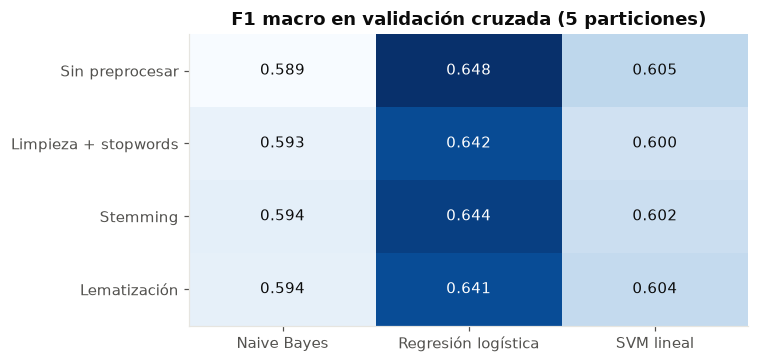

Mejor combinación: Regresión logística con 'Sin preprocesar' (F1 macro = 0.648 ± 0.005)


In [14]:
tabla = comparacion.pivot(index="preprocesamiento", columns="modelo", values="f1_macro").reindex(VARIANTES)
fig, ax = plt.subplots(figsize=(7, 3.4))
im = ax.imshow(tabla.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(tabla.shape[1]), tabla.columns)
ax.set_yticks(range(tabla.shape[0]), tabla.index)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        v = tabla.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                color=color_texto(v, tabla.values), fontsize=10)
ax.set_title("F1 macro en validación cruzada (5 particiones)")
ax.grid(False)
plt.tight_layout(); plt.show()

mejor = comparacion.loc[comparacion["f1_macro"].idxmax()]
COL_MEJOR, MODO_MEJOR = VARIANTES[mejor["preprocesamiento"]]
print(f"Mejor combinación: {mejor['modelo']} con '{mejor['preprocesamiento']}' "
      f"(F1 macro = {mejor['f1_macro']:.3f} ± {mejor['desv']:.3f})")

Con la mejor combinación se entrena el modelo final con todo el 80 % de entrenamiento y se evalúa una sola vez en el 20 % de prueba, que el modelo no vio antes.

Prueba final  ->  F1 macro: 0.650  |  exactitud: 0.855

              precision    recall  f1-score   support

    negativo      0.884     0.896     0.890      1933
      neutro      0.137     0.185     0.157       189
    positivo      0.926     0.880     0.903      1868

    accuracy                          0.855      3990
   macro avg      0.649     0.654     0.650      3990
weighted avg      0.868     0.855     0.861      3990



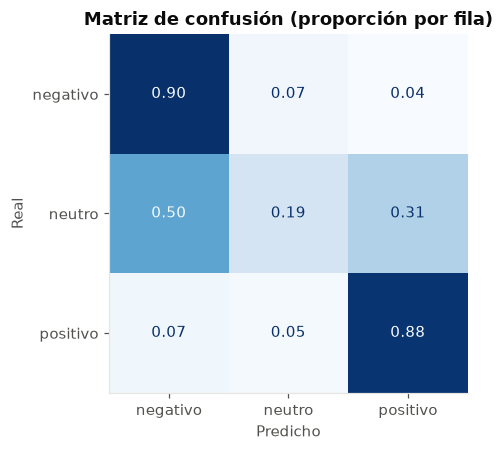

In [15]:
modelo_sent = Pipeline([("tfidf", crear_tfidf()), ("clf", MODELOS[mejor["modelo"]]())])
modelo_sent.fit(df_modelo.loc[idx_train, COL_MEJOR], y.loc[idx_train])
pred_test = modelo_sent.predict(df_modelo.loc[idx_test, COL_MEJOR])

f1_test = f1_score(y.loc[idx_test], pred_test, average="macro")
acc_test = accuracy_score(y.loc[idx_test], pred_test)
print(f"Prueba final  ->  F1 macro: {f1_test:.3f}  |  exactitud: {acc_test:.3f}\n")
print(classification_report(y.loc[idx_test], pred_test, labels=ORDEN_SENT, digits=3))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y.loc[idx_test], pred_test, labels=ORDEN_SENT,
                                        normalize="true", values_format=".2f",
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Matriz de confusión (proporción por fila)")
ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.grid(False)
plt.tight_layout(); plt.show()

**¿Qué palabras usa el modelo para decidir?** Se entrena una regresión logística sobre el texto lematizado y se miran sus coeficientes. Un coeficiente alto para la clase "negativo" significa que esa palabra empuja la predicción hacia negativo.

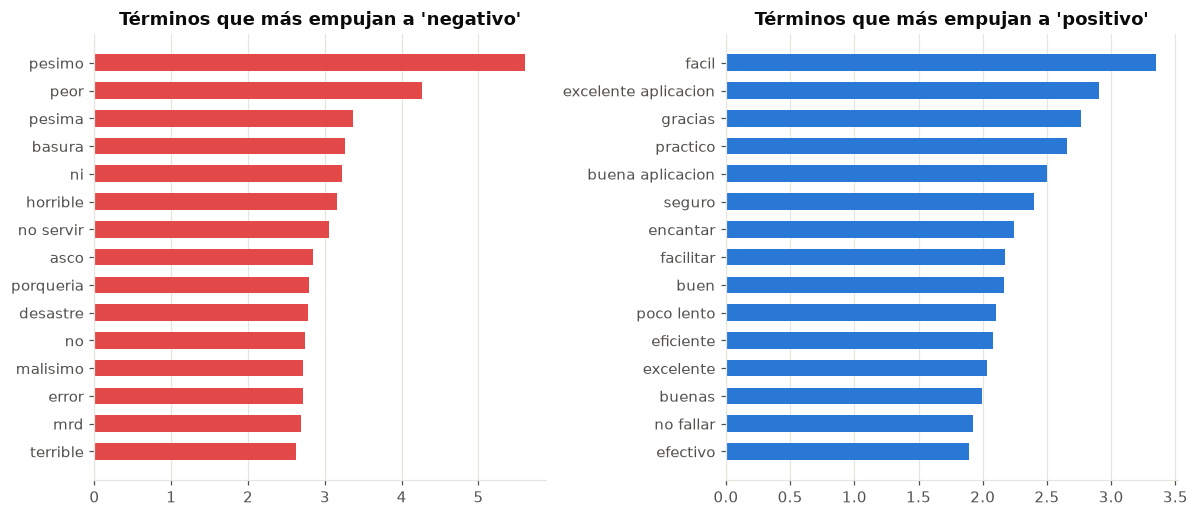

In [16]:
interp = Pipeline([("tfidf", crear_tfidf()),
                   ("clf", LogisticRegression(max_iter=3000, C=2.0, class_weight="balanced"))])
interp.fit(df_modelo.loc[idx_train, "texto_lema"], y.loc[idx_train])
vocab = np.array(interp.named_steps["tfidf"].get_feature_names_out())
clases = list(interp.named_steps["clf"].classes_)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, s in zip(axes, ["negativo", "positivo"]):
    coef = interp.named_steps["clf"].coef_[clases.index(s)]
    top = coef.argsort()[::-1][:15]
    ax.barh(vocab[top][::-1], coef[top][::-1], color=COLORES_SENT[s], height=0.6)
    ax.set_title(f"Términos que más empujan a '{s}'")
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [17]:
# Análisis de errores: reseñas de prueba que el modelo clasificó mal
errores = df_modelo.loc[idx_test].assign(predicho=pred_test)
errores = errores[errores["sentimiento"] != errores["predicho"]]
print(f"Errores en prueba: {len(errores):,} de {len(idx_test):,}")
errores.sample(min(8, len(errores)), random_state=SEMILLA)[["app", "score", "sentimiento", "predicho", "content"]]

Errores en prueba: 579 de 3,990


,app,score,sentimiento,predicho,content
2293,Yape,4,positivo,negativo,"Quisiera saber por qué en mi yape no puedo visualizar el icono de crédito y el icono de código de aprobación ,ya hize de todo pero no me..."
129,Yape,5,positivo,negativo,no tengo la opción creditos
7509,BCP,3,neutro,negativo,"Excelente aplicación, pero sus mantenimientos deben hacerlo por la noche o madrugada, a veces en el día tenemos una emergencia y sale ""e..."
4758,BCP,1,negativo,positivo,Caido
9603,Interbank,3,neutro,positivo,"la interfaz anterior me gustaba más, muy amigable e intuitiva, me gustaba mucho su app, la nueva interfaz es lo contrario."
11253,Interbank,3,neutro,negativo,"cuando se quería plinear a veces fallaba, de ahí sacaron algo positivo de que se ponía plinear con tarjeta de crédito, comenze a usar el..."
7499,BCP,3,neutro,positivo,mejorar la opción para pagar créditos BCP
12734,BBVA,3,neutro,positivo,bien


> **Interpretación:** [completar: qué preprocesamiento y qué modelo ganaron, qué clase se confunde más (normalmente la neutra) y ejemplos de errores, como reseñas de 5 estrellas con queja o sarcasmo]

**Comparación con un modelo preentrenado (opcional).** `pysentimiento` usa RoBERTuito, un modelo de lenguaje entrenado con tuits en español (Pérez et al., 2021). Se compara con nuestro modelo en una muestra de la partición de prueba. Necesita internet y tarda unos minutos, por eso se puede desactivar.

In [18]:
USAR_PYSENTIMIENTO = True
resultado_pysent = None
if USAR_PYSENTIMIENTO:
    try:
        # !pip install -q pysentimiento
        from pysentimiento import create_analyzer
        analizador = create_analyzer(task="sentiment", lang="es")
        muestra = df_modelo.loc[idx_test].sample(min(600, len(idx_test)), random_state=SEMILLA)
        mapa = {"NEG": "negativo", "NEU": "neutro", "POS": "positivo"}
        pred_py = [mapa[r.output] for r in analizador.predict(muestra["content"].tolist())]
        pred_nuestro = modelo_sent.predict(muestra[COL_MEJOR])
        resultado_pysent = pd.DataFrame({
            "modelo": [f"Nuestro modelo ({mejor['modelo']})", "pysentimiento (RoBERTuito)"],
            "f1_macro": [f1_score(muestra["sentimiento"], pred_nuestro, average="macro"),
                         f1_score(muestra["sentimiento"], pred_py, average="macro")],
            "exactitud": [accuracy_score(muestra["sentimiento"], pred_nuestro),
                          accuracy_score(muestra["sentimiento"], pred_py)],
        }).round(3)
        display(resultado_pysent)
    except Exception as e:
        print("No se pudo ejecutar pysentimiento:", e)

No se pudo ejecutar pysentimiento: No module named 'pysentimiento'


### 5.3 Clasificación del tipo de reclamo (reglas con expresiones regulares)

El sentimiento dice si el usuario está molesto, pero no por qué. Para eso se definieron siete tipos de reclamo, cada uno con un grupo de expresiones regulares. Las reglas se aplican sobre el texto normalizado (minúsculas, sin tildes y con la jerga corregida).

Una reseña puede tener varios tipos. El tipo principal es el que tiene más coincidencias; si hay empate, se usa el orden de la tabla, que va de lo más grave a lo menos grave.

Se eligieron reglas en vez de un modelo supervisado porque no existe una base peruana de reclamos bancarios etiquetada por tipo. Las reglas además son fáciles de explicar y de corregir.

In [19]:
pd.DataFrame([{"tipo de reclamo": c, "n.° de patrones": len(p),
               "algunos patrones": "  ".join(p[:4])} for c, p in CATEGORIAS.items()])

,tipo de reclamo,n.° de patrones,algunos patrones
0,Seguridad y fraude,12,\brob(o|aron|ado|ada)\b \bfraud \bestaf \bhacke
1,Transferencias y pagos,14,\btransfer \btransaccion \byape(o|ar|ado|aron|aste)\b \bplin\b
2,Acceso y validación,18,\blogin\b \biniciar sesion\b \bingres(ar|o)\b \bentrar\b
3,Comisiones y límites,9,\bcomision \bcobr(o|an|aron|ar|aran)\b \blimite \btope\b
4,Actualizaciones y compatibilidad,8,\bactuali[zc] \bversion\b \bcompatib \broot
5,Fallas técnicas,16,\bse (cuelga|traba|cierra|congela|cae|colgo|cerro)\b \berror\b \bfall(a|as|o|ando)\b \blent[oa]\b
6,Atención al cliente,11,\batencion\b \basesor \bcall ?center\b \blinea\b


Reseñas negativas con al menos un tipo de reclamo: 76.8 %


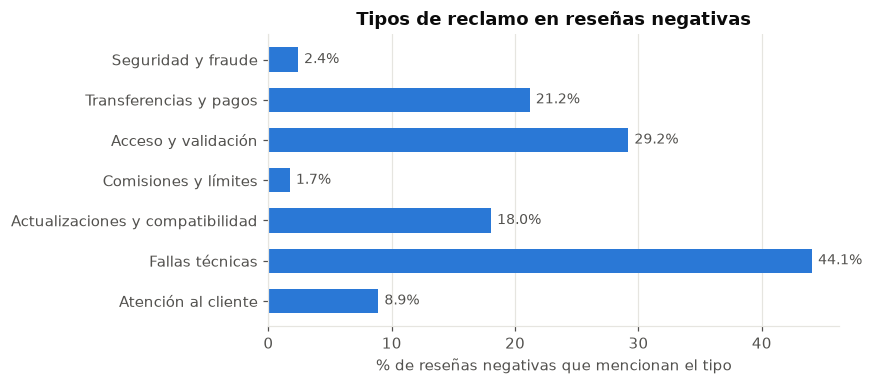

In [20]:
resultado = df_modelo["content"].apply(clasificar_reclamo)
df_modelo["categoria_principal"] = resultado.str["principal"]
df_modelo["categorias"] = resultado.str["categorias"]
neg = df_modelo[df_modelo["sentimiento"] == "negativo"]

cobertura = (neg["categoria_principal"] != SIN_CATEGORIA).mean() * 100
print(f"Reseñas negativas con al menos un tipo de reclamo: {cobertura:.1f} %")

pct_tipo = (neg["categorias"].explode().value_counts() / len(neg) * 100).reindex(CATEGORIAS).fillna(0)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(pct_tipo.index[::-1], pct_tipo.values[::-1], color="#2a78d6", height=0.6)
for i, v in enumerate(pct_tipo.values[::-1]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("% de reseñas negativas que mencionan el tipo")
ax.set_title("Tipos de reclamo en reseñas negativas")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [21]:
# Un ejemplo por tipo de reclamo
neg[neg["categoria_principal"] != SIN_CATEGORIA].groupby("categoria_principal") \
   .sample(1, random_state=SEMILLA)[["categoria_principal", "app", "content"]]

,categoria_principal,app,content
4447,Acceso y validación,BCP,no me deja ingresar a la app 😔
12709,Actualizaciones y compatibilidad,BBVA,"Con la ultima actualización, se perdieron mis operaciones frecuentes grabadas, y no me deja crear otras , todos los botones fallan, meji..."
7848,Atención al cliente,BCP,"Perdi mi tarjeta y saque otra . Hace dos meses que trato de abrir mi banca movil con el nuevo numero de cuenta pero nada . Me redirige ,..."
2277,Comisiones y límites,Yape,"Hay muchos problemas para identificación de rostro, llevo varios días y no hay ningún tipo de interés de brindarme ayuda. Me repiten las..."
19125,Fallas técnicas,Scotiabank,"muy mala aplicación, falla y se desconecta a cada rato. que supuestamente mantenimiento. aparte las transferencias por Plim son una desg..."
3757,Seguridad y fraude,Yape,la verda me robaron el celular y no puedo recuperaf mi dinero cuenta dni esta resgistado con mi numero de celular nada
133,Transferencias y pagos,Yape,"En la última actualización , dejo de tener el limitador de transacciones de 500 a 2000 soles ,pésimo dejaré de usarlo y me pasaré a PLIN :/"


**Validación de las reglas.** Para saber qué tan bien funcionan las reglas, el grupo revisa a mano una muestra de reseñas negativas. La celda de abajo crea el archivo `data/validacion_reclamos.csv`. Se llena la columna `categoria_real` con el tipo correcto (usando los mismos nombres) y se vuelve a ejecutar la celda para obtener la exactitud de las reglas.

In [22]:
RUTA_VALIDACION = "data/validacion_reclamos.csv"
if os.path.exists(RUTA_VALIDACION):
    val = pd.read_csv(RUTA_VALIDACION).dropna(subset=["categoria_real"])
    if len(val):
        print(f"Reseñas revisadas a mano: {len(val)}")
        print(f"Exactitud del tipo principal: {(val['categoria_regla'] == val['categoria_real']).mean():.3f}\n")
        print(classification_report(val["categoria_real"], val["categoria_regla"], zero_division=0))
    else:
        print("El archivo existe, pero la columna categoria_real todavía está vacía.")
else:
    (neg.sample(min(150, len(neg)), random_state=SEMILLA)
        [["reviewId", "app", "content", "categoria_principal"]]
        .rename(columns={"categoria_principal": "categoria_regla"})
        .assign(categoria_real="")
        .to_csv(RUTA_VALIDACION, index=False, encoding="utf-8"))
    print(f"Se creó {RUTA_VALIDACION}. Completen 'categoria_real' y vuelvan a ejecutar esta celda.")

Se creó data/validacion_reclamos.csv. Completen 'categoria_real' y vuelvan a ejecutar esta celda.


### 5.4 Modelado de temas (LDA)

Las reglas solo encuentran lo que ya se definió. LDA (Latent Dirichlet Allocation; Blei et al., 2003) descubre temas sin decirle cuáles buscar. Supone que cada reseña es una mezcla de temas y que cada tema es una distribución de palabras. El modelo estima dos cosas:

- $\theta_d$: la proporción de cada tema en la reseña $d$.
- $\phi_k$: la probabilidad de cada palabra dentro del tema $k$.

Se aplica solo a reseñas negativas con al menos 4 palabras, porque las muy cortas no tienen suficiente información. Se usa el texto sin nombres de bancos y se quitan palabras de opinión general ("no", "mal", "pésimo"), que aparecen en todos los temas.

**¿Cuántos temas?** Se prueba de 3 a 10 temas y se mide:
- **Perplejidad** en un 20 % de reseñas reservadas: mientras más baja, mejor predice el modelo textos nuevos.
- **Coherencia UMass** (Mimno et al., 2011): mide si las palabras principales de cada tema suelen aparecer juntas en las mismas reseñas. Mientras más cerca de 0, más coherente.

$$C_{UMass}(k) = \sum_{i=2}^{M}\sum_{j=1}^{i-1} \ln\frac{D(w_i, w_j) + 1}{D(w_j)}$$

donde $D(w_i, w_j)$ es el número de reseñas que tienen las dos palabras y $D(w_j)$ el número de reseñas con $w_j$.

In [23]:
%%time
STOP_TEMAS = ["no", "ni", "nada", "sin", "mal", "bien", "mucho", "muchos", "poco", "siempre",
              "bueno", "buena", "mejor", "peor", "pesimo", "pesima", "gran", "demasiado",
              "tarde", "nunca", "favor", "hacer", "poder", "dar", "decir", "querer", "malo"]
neg_largas = neg[neg["n_palabras"] >= 4]
vec_lda = CountVectorizer(min_df=5, max_df=0.4, stop_words=STOP_TEMAS,
                          token_pattern=r"(?u)\b(?!emoji_)[a-zñ]{3,}\b")
X_lda = vec_lda.fit_transform(neg_largas["texto_tema"])
vocab_lda = np.array(vec_lda.get_feature_names_out())
print(f"Reseñas: {X_lda.shape[0]:,}  |  vocabulario: {X_lda.shape[1]:,}")

Xb = (X_lda > 0).astype(np.int32).tocsc()
D = np.asarray(Xb.sum(axis=0)).ravel()
co = (Xb.T @ Xb).tocsr()

def coherencia_umass(modelo, n_top=10):
    puntajes = []
    for comp in modelo.components_:
        top = comp.argsort()[::-1][:n_top]
        s = sum(np.log((co[top[i], top[j]] + 1) / D[top[j]])
                for i in range(1, len(top)) for j in range(i))
        puntajes.append(s)
    return float(np.mean(puntajes))

X_tr_lda, X_val_lda = train_test_split(X_lda, test_size=0.2, random_state=SEMILLA)
busqueda = []
for k in range(3, 11):
    lda_k = LatentDirichletAllocation(n_components=k, learning_method="batch",
                                      max_iter=25, random_state=SEMILLA).fit(X_tr_lda)
    busqueda.append({"temas": k, "perplejidad": lda_k.perplexity(X_val_lda),
                     "coherencia_umass": coherencia_umass(lda_k)})
busqueda = pd.DataFrame(busqueda)
busqueda.round(2)

Reseñas: 8,697  |  vocabulario: 1,212


CPU times: total: 3min 10s
Wall time: 3min 15s


,temas,perplejidad,coherencia_umass
0,3,691.32,-118.41
1,4,773.01,-119.12
2,5,833.89,-121.91
3,6,909.00,-127.68
4,7,961.60,-129.44
5,8,1037.16,-132.03
6,9,1103.16,-136.34
7,10,1171.61,-127.03


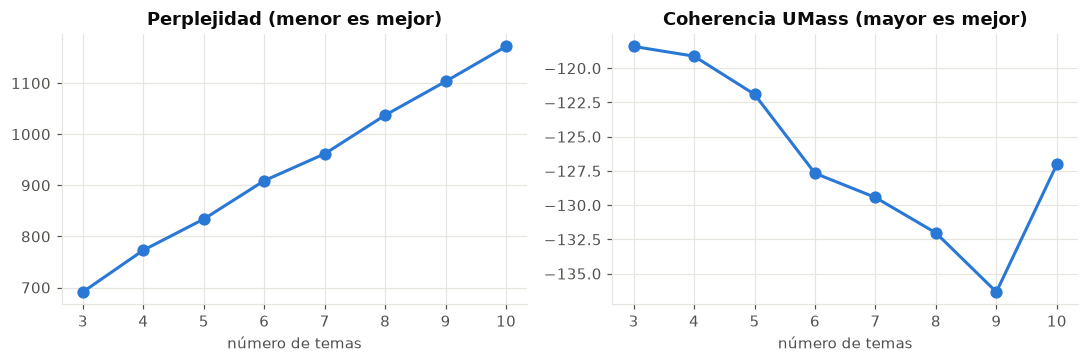

Número de temas elegido: 3


In [24]:
# Dos gráficos separados (cada medida tiene su propia escala)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col, titulo in zip(axes, ["perplejidad", "coherencia_umass"],
                           ["Perplejidad (menor es mejor)", "Coherencia UMass (mayor es mejor)"]):
    ax.plot(busqueda["temas"], busqueda[col], marker="o", color="#2a78d6", markersize=7)
    ax.set_title(titulo); ax.set_xlabel("número de temas")
plt.tight_layout(); plt.show()

N_TEMAS = None   # se puede fijar a mano después de leer los temas, por ejemplo N_TEMAS = 6
if N_TEMAS is None:
    N_TEMAS = int(busqueda.loc[busqueda["coherencia_umass"].idxmax(), "temas"])
print("Número de temas elegido:", N_TEMAS)

In [25]:
lda = LatentDirichletAllocation(n_components=N_TEMAS, learning_method="batch",
                                max_iter=40, random_state=SEMILLA).fit(X_lda)
temas_top = [list(vocab_lda[c.argsort()[::-1][:10]]) for c in lda.components_]

# Nombre de cada tema: por defecto sus 3 palabras principales.
# Después de leerlos, se pueden renombrar a mano, por ejemplo {0: "Validación de identidad"}.
ETIQUETAS_TEMAS = {}
etiquetas = [ETIQUETAS_TEMAS.get(i, ", ".join(p[:3])) for i, p in enumerate(temas_top)]

theta = lda.transform(X_lda)
neg_largas = neg_largas.assign(tema=theta.argmax(axis=1))
peso = pd.Series(theta.argmax(axis=1)).value_counts(normalize=True).sort_index() * 100

pd.DataFrame({"tema": range(N_TEMAS), "nombre": etiquetas,
              "% de reseñas": peso.reindex(range(N_TEMAS)).fillna(0).round(1).values,
              "10 palabras principales": [", ".join(p) for p in temas_top]})

,tema,nombre,% de reseñas,10 palabras principales
0,0,"funcionar, abrir, actualizar",38.3,"funcionar, abrir, actualizar, actualizacion, servicio, ingresar, mantenimiento, pagar, fallar, quedar"
1,1,"error, salir, entrar",36.0,"error, salir, entrar, dinero, dejar, lento, pago, problema, ingresar, falla"
2,2,"ingresar, clave, pedir",25.7,"ingresar, clave, pedir, tarjeta, instalar, dejar, permitir, salir, problema, llegar"


In [26]:
# Ejemplos: la reseña con mayor peso en cada tema
for k in range(N_TEMAS):
    i = theta[:, k].argmax()
    print(f"Tema {k} ({etiquetas[k]}):  {neg_largas.iloc[i]['content'][:220]}\n")

Tema 0 (funcionar, abrir, actualizar):  Creí que era mi teléfono, la señal cualquier otra cosa menos la app; hasta que leí las otras reseñas, la app no funciona casi nada, tarda un montón para cargar y si abre se cuelga totalmente, la espera desespera porque e

Tema 1 (error, salir, entrar):  está app cada día que pasa se vuelve más inservible estoy tratando de enviar dinero Y ME SALE UN AVISO QUE HUBO UN INCONVENIENTE EL DINERO NO PUDO ENVIARSE VUELVE A INTENTARLO lo vuelvo a intentar y me sale el mismo mens

Tema 2 (ingresar, clave, pedir):  Pésimo. Más de 2 meses que no puedo usarla. Intento crear usuario y luego de confirmar mis datos (foto y correo-e), nunca llega la clave al único correo-e registrado en el banco hace casi 20 años. Pero en ese mismo corre



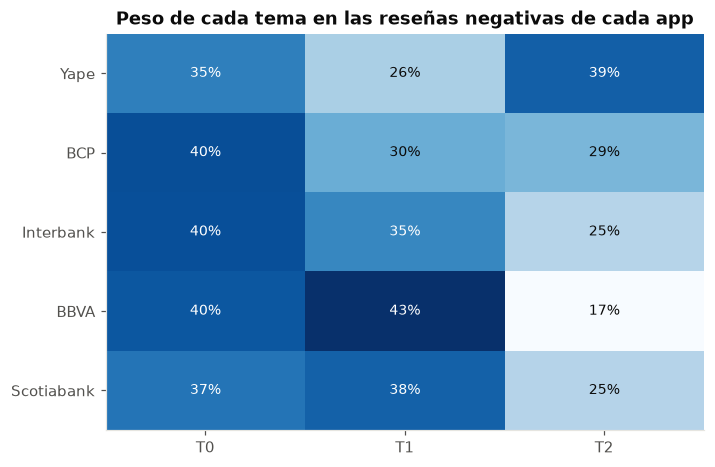

In [27]:
temas_app = (pd.crosstab(neg_largas["app"], neg_largas["tema"], normalize="index")
               .reindex(index=apps, columns=range(N_TEMAS)).fillna(0) * 100)
fig, ax = plt.subplots(figsize=(1.2 * N_TEMAS + 3, 0.55 * len(apps) + 1.6))
ax.imshow(temas_app.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(N_TEMAS), [f"T{k}" for k in range(N_TEMAS)])
ax.set_yticks(range(len(apps)), apps)
for i in range(temas_app.shape[0]):
    for j in range(temas_app.shape[1]):
        v = temas_app.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center",
                color=color_texto(v, temas_app.values), fontsize=9)
ax.set_title("Peso de cada tema en las reseñas negativas de cada app")
ax.grid(False)
plt.tight_layout(); plt.show()

> **Interpretación:** [completar: nombrar cada tema según sus palabras, ver si coinciden con los tipos de reclamo de 5.3 y qué tema predomina en cada app]

### 5.5 Similitud semántica (LSA + similitud coseno)

El objetivo es que, dada una queja, la app muestre otras reseñas que cuentan el mismo problema aunque usen palabras distintas ("me descontaron plata" y "me cobraron sin avisar").

TF-IDF solo compara palabras exactas. Por eso se aplica LSA (Latent Semantic Analysis; Deerwester et al., 1990): una descomposición en valores singulares truncada de la matriz TF-IDF, que agrupa palabras que suelen aparecer en contextos parecidos.

$$X \approx U_k \Sigma_k V_k^{T}$$

Cada reseña queda como un vector de $k$ dimensiones. La similitud entre dos reseñas se mide con el coseno del ángulo entre sus vectores:

$$\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$$

Vale 1 si las reseñas apuntan en la misma dirección y 0 si no tienen nada en común.

In [28]:
vec_lsa = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
X_tfidf = vec_lsa.fit_transform(df_modelo["texto_tema"])
n_comp = min(150, X_tfidf.shape[1] - 1)
svd = TruncatedSVD(n_components=n_comp, random_state=SEMILLA)
Z = normalize(svd.fit_transform(X_tfidf)).astype(np.float32)
print(f"Matriz TF-IDF: {X_tfidf.shape}  ->  LSA: {Z.shape}")
print(f"Varianza explicada por {n_comp} componentes: {svd.explained_variance_ratio_.sum():.1%}")

def ver_similares(consulta, k=5):
    idx, sims = buscar_similares(consulta, vec_lsa, svd, Z, k=k * 4, nlp=nlp)
    if len(idx) == 0:
        print("Ninguna palabra de la consulta aparece en el vocabulario.")
        return None
    res = df_modelo.iloc[idx][["app", "score", "content"]].assign(similitud=sims.round(3))
    return res.drop_duplicates("content").head(k)   # sin textos repetidos

ver_similares("me descontaron plata de mi cuenta y nadie me explica")

Matriz TF-IDF: (19946, 12850)  ->  LSA: (19946, 150)
Varianza explicada por 150 componentes: 47.9%


,app,score,content,similitud
1882,Yape,1,me robó mi plata,0.878
7215,BCP,1,se me roban la plata,0.878
15398,BBVA,1,son ladrones me Han robado mi plata,0.875
4012,BCP,1,Se está agarrando mi plata es injusto uno con tanto esfuerzo trabaje y la apta se agarro mil soles y no me quiere devolver,0.826
1507,Yape,1,antiguamente la usaba pero últimamente está aplicación me está robando se me desaparecieron 400 soles,0.800


In [29]:
ver_similares("no puedo entrar porque no reconoce mi cara en la validación")

,app,score,content,similitud
17507,Scotiabank,1,"su reconocimiento facil no reconoce, ya no se puede entrar a su aplicativo. pesima actualización.",0.768
7850,BCP,2,aveces no entra la APP,0.761
11816,Interbank,1,no entra el aplicativo nooo,0.758
2099,Yape,1,No entra el lector facilmente,0.749
5002,BCP,1,No entra la appp,0.747


### 5.6 Extracción de información (expresiones regulares + NER)

Se extraen datos concretos que ayudan a entender el reclamo:

- **Con expresiones regulares:** montos (`S/ 50`, `100 soles`), fechas y tiempos (`ayer`, `hace 3 días`, `12/10`), versión de la app, marcas de celular, entidades financieras y operadores móviles.
- **Con NER (reconocimiento de entidades nombradas) de spaCy:** personas (PER), organizaciones (ORG) y lugares (LOC) que aparecen en el texto.

El modelo de NER de spaCy se entrenó con textos de noticias. En reseñas informales confunde palabras que van al inicio con mayúscula ("Hola", "Pésimo", "Uff") con nombres propios. Por eso se aplica un filtro: se descartan esas palabras y las entidades de una sola palabra al inicio de una oración, salvo que sean marcas o entidades conocidas. Más abajo se comparan los resultados con y sin filtro.

Reseñas negativas que mencionan un monto: 1.2 %


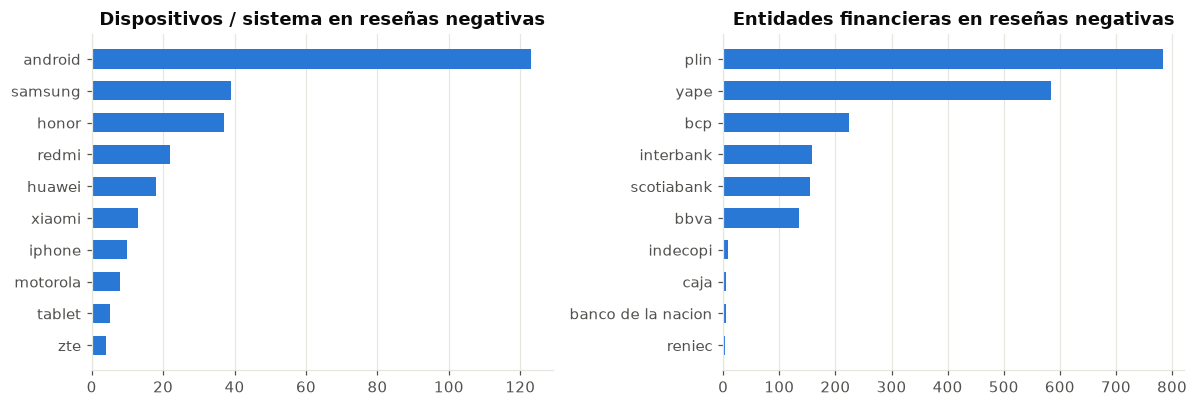

CPU times: total: 3.16 s
Wall time: 3.29 s


In [30]:
%%time
info_neg = neg["content"].apply(lambda t: extraer_informacion(t, usar_ner=False))

pct_monto = info_neg.apply(lambda d: len(d["Montos"]) > 0).mean() * 100
print(f"Reseñas negativas que mencionan un monto: {pct_monto:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, campo in zip(axes, ["Dispositivos / sistema", "Entidades financieras"]):
    conteo = Counter(x for d in info_neg for x in d[campo]).most_common(10)
    if not conteo:
        ax.set_visible(False); continue
    nombres, valores = zip(*conteo)
    ax.barh(nombres[::-1], valores[::-1], color="#2a78d6", height=0.6)
    ax.set_title(f"{campo} en reseñas negativas")
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [31]:
%%time
# NER de spaCy en una muestra (es más lento que las regex)
muestra_ner = neg.sample(min(800, len(neg)), random_state=SEMILLA)["content"]
sin_filtro, con_filtro = Counter(), Counter()
for doc in nlp.pipe([preparar_para_ner(t) for t in muestra_ner], batch_size=128):
    for e in doc.ents:
        if e.label_ in {"PER", "ORG", "LOC"}:
            sin_filtro[(e.text.lower(), e.label_)] += 1
    for ent in entidades_ner(doc):
        con_filtro[ent.lower()] += 1

print("NER de spaCy sin filtro (10 más frecuentes):")
print([f"{t} [{l}] x{n}" for (t, l), n in sin_filtro.most_common(10)], "\n")
pd.DataFrame(con_filtro.most_common(15), columns=["entidad [tipo]", "menciones"])

NER de spaCy sin filtro (10 más frecuentes):
['app [ORG] x115', 'plin [PER] x40', 'bbva [ORG] x17', 'pésimo [PER] x15', 'plin [LOC] x14', 'yape [PER] x11', 'interbank [PER] x10', 'app [PER] x9', 'bcp [ORG] x7', 'está [PER] x7'] 

CPU times: total: 2.3 s
Wall time: 2.89 s


,entidad [tipo],menciones
0,plin [per],40
1,bbva [org],17
2,plin [loc],14
3,yape [per],11
4,interbank [per],10
5,bcp [org],7
6,google [org],5
7,plim [per],4
8,scotiabank [loc],4
9,yape [org],4


In [32]:
# Ejemplo completo de extracción sobre una reseña con monto
con_monto = neg[info_neg.apply(lambda d: len(d["Montos"]) > 0)]
if len(con_monto):
    ejemplo = con_monto.iloc[0]["content"]
    print(ejemplo, "\n")
    for campo, valores in extraer_informacion(ejemplo, nlp=nlp).items():
        print(f"{campo}: {valores}")

pésima aplicación, me sustrajeron 98 soles el día de ayer y me comunique con soporte y nada , les espera su denuncia ante Indecopi 

Montos: ['98 soles']
Fechas / tiempo: ['ayer']
Versión de la app: []
Dispositivos / sistema: []
Entidades financieras: ['indecopi']
Operadores móviles: []
NER spaCy (PER/ORG/LOC): ['Indecopi [LOC]']


## 6. Análisis comparativo entre bancos

Con los resultados de las técnicas anteriores se comparan las cinco apps.

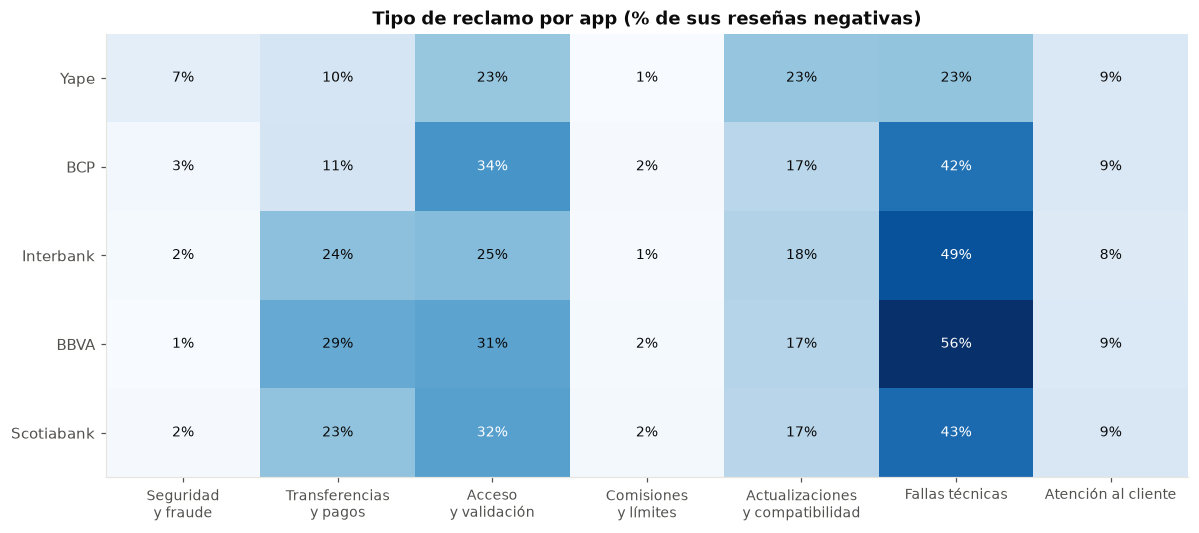

In [33]:
# Tipo de reclamo por app (% de reseñas negativas de cada app que mencionan el tipo)
filas = []
for app in apps:
    sub = neg[neg["app"] == app]
    conteo = sub["categorias"].explode().value_counts()
    filas.append((conteo / len(sub) * 100).rename(app))
tipo_app = pd.DataFrame(filas).reindex(columns=list(CATEGORIAS)).fillna(0)

fig, ax = plt.subplots(figsize=(11, 0.55 * len(apps) + 2.2))
ax.imshow(tipo_app.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(tipo_app.shape[1]), [c.replace(" y ", "\ny ") for c in tipo_app.columns], fontsize=9)
ax.set_yticks(range(len(apps)), tipo_app.index)
for i in range(tipo_app.shape[0]):
    for j in range(tipo_app.shape[1]):
        v = tipo_app.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center",
                color=color_texto(v, tipo_app.values), fontsize=9)
ax.set_title("Tipo de reclamo por app (% de sus reseñas negativas)")
ax.grid(False)
plt.tight_layout(); plt.show()

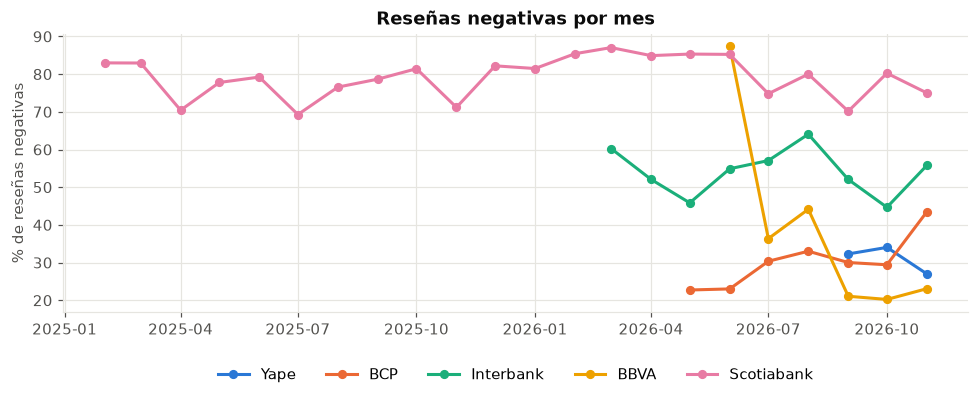

In [34]:
# Evolución mensual del % de reseñas negativas (solo meses con 30 reseñas o más)
mensual = (df_modelo.assign(mes=df_modelo["fecha"].dt.to_period("M").dt.to_timestamp(),
                            es_neg=df_modelo["sentimiento"] == "negativo")
           .groupby(["app", "mes"]).agg(n=("es_neg", "size"), pct_neg=("es_neg", "mean")).reset_index())
mensual = mensual[mensual["n"] >= 30]

fig, ax = plt.subplots(figsize=(9, 3.8))
for app in apps:
    sub = mensual[mensual["app"] == app]
    if len(sub):
        ax.plot(sub["mes"], sub["pct_neg"] * 100, marker="o", markersize=5,
                color=COLORES_APP[app], label=app)
ax.set_ylabel("% de reseñas negativas")
ax.set_title("Reseñas negativas por mes")
ax.legend(ncol=len(apps), loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.show()

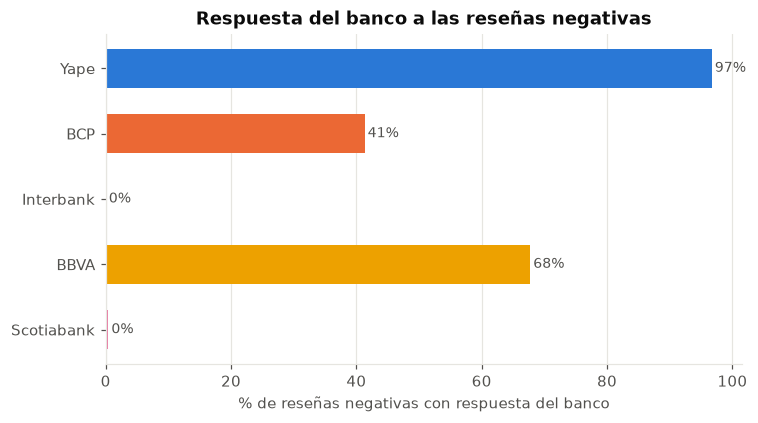

In [35]:
# ¿El banco responde las reseñas negativas?
respuesta = neg.groupby("app").agg(
    negativas=("reviewId", "size"),
    pct_respondidas=("respondida", lambda s: s.mean() * 100),
).reindex(apps)

fig, ax = plt.subplots(figsize=(7, 0.55 * len(apps) + 1.2))
ax.barh(respuesta.index[::-1], respuesta["pct_respondidas"][::-1],
        color=[COLORES_APP[a] for a in respuesta.index[::-1]], height=0.6)
for i, v in enumerate(respuesta["pct_respondidas"][::-1]):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("% de reseñas negativas con respuesta del banco")
ax.set_title("Respuesta del banco a las reseñas negativas")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [36]:
# Reseñas negativas con más "me gusta" (problemas con los que otros usuarios se identifican)
neg.nlargest(10, "thumbsUpCount")[["app", "thumbsUpCount", "categoria_principal", "content"]]

,app,thumbsUpCount,categoria_principal,content
6389,BCP,5588,Acceso y validación,Nuevamente de verdad que MOLESTIA que OBLIGEN a realizar actualización de la app en el momento que uno lo va a usar. Si es una emergenci...
16281,Scotiabank,1127,Fallas técnicas,"Terrible la experiencia, te corta la sesión aún cuando se está trabajando, te pide constantemente que ingreses la tarjeta como si fuera ..."
19427,Scotiabank,448,Acceso y validación,"La aplicación presenta serios problemas de rendimiento y estabilidad. Con frecuencia, tras iniciar sesión, se cierra abruptamente con el..."
17428,Scotiabank,277,Fallas técnicas,"El aplicativo es pésimo, a cada rato me sale Mantenimiento Programado, sobre todo x las noches. Y realmente es cansado que a diario pase..."
13610,BBVA,216,Actualizaciones y compatibilidad,"En la última actualización, se ha generado un error en la opción de plin, cuando deseo buscar el contacto para generar el plin me pide p..."
17917,Scotiabank,198,Transferencias y pagos,"Terrible. Al inicio me parecía funcional y con opciones novedosas que no encontraba en otros aplicativos bancarios; sin embargo, su serv..."
16971,Scotiabank,167,Acceso y validación,"Cada vez está peor, quiero entrar a la aplicación y sale ""hubo un error en la aplicación inténtalo más tarde"" y cuando por fin ingreso y..."
9474,Interbank,164,Transferencias y pagos,"Que estupidez de aplicación, hice un reclamo porque no ingreso el abono de una transacción, envié las capturas de pantalla de mi estado ..."
9130,Interbank,151,Transferencias y pagos,Intento hacer una transferencia mínima de menos de 100 soles y llevo esperando 2 horas y me sale . Lo sentimos no se pudo realizar la op...
18514,Scotiabank,123,Acceso y validación,Qué experiencia para más desagradable usar su aplicación. Trato de configurarla de tal manera que pueda utilizar mi huella para acceder ...


> **Interpretación:** [completar: qué tipo de reclamo pesa más en cada banco, si hubo meses con más quejas y qué banco responde más]

## 7. Exportación de modelos y datos para la app

Se guardan los archivos que lee `app.py`:

| Archivo | Contenido |
|---|---|
| `models/modelo_sentimiento.joblib` | Pipeline TF-IDF + clasificador y el modo de preprocesamiento |
| `models/modelo_temas.joblib` | Vectorizador, modelo LDA y nombres de los temas |
| `models/modelo_lsa.joblib` | Vectorizador TF-IDF y SVD para la similitud |
| `models/lsa_matriz.npy` | Reseñas proyectadas en el espacio LSA |
| `models/metricas.json` | Métricas y resumen del proyecto |
| `data/processed/resenas_procesadas.csv` | Reseñas con sentimiento, tipo de reclamo y tema |

In [37]:
df_modelo["tema"] = np.nan
df_modelo.loc[neg_largas.index, "tema"] = neg_largas["tema"]

salida = df_modelo[["reviewId", "app", "fecha", "score", "sentimiento", "content", "texto_tema",
                    "categoria_principal", "categorias", "tema", "respondida", "thumbsUpCount",
                    "reviewCreatedVersion"]].copy()
salida["categorias"] = salida["categorias"].apply("; ".join)
salida.to_csv("data/processed/resenas_procesadas.csv", index=False, encoding="utf-8")

joblib.dump({"pipeline": modelo_sent, "modo": MODO_MEJOR, "modelo": mejor["modelo"],
             "preprocesamiento": mejor["preprocesamiento"]}, "models/modelo_sentimiento.joblib")
joblib.dump({"vectorizador": vec_lda, "lda": lda, "etiquetas": etiquetas,
             "palabras": temas_top}, "models/modelo_temas.joblib")
joblib.dump({"vectorizador": vec_lsa, "svd": svd}, "models/modelo_lsa.joblib")
np.save("models/lsa_matriz.npy", Z)

reporte = classification_report(y.loc[idx_test], pred_test, labels=ORDEN_SENT, output_dict=True)
metricas = {
    "fecha_ejecucion": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "n_resenas": int(len(df_modelo)),
    "por_app": {a: int((df_modelo["app"] == a).sum()) for a in apps},
    "periodo": {a: [str(resumen.loc[a, "desde"]), str(resumen.loc[a, "hasta"])] for a in apps},
    "sentimiento": {
        "modelo": mejor["modelo"], "preprocesamiento": mejor["preprocesamiento"],
        "f1_macro_cv": round(float(mejor["f1_macro"]), 4),
        "f1_macro_test": round(float(f1_test), 4), "exactitud_test": round(float(acc_test), 4),
        "reporte_test": reporte,
        "comparacion": comparacion.round(4).to_dict(orient="records"),
        "pysentimiento": None if resultado_pysent is None else resultado_pysent.to_dict(orient="records"),
    },
    "reclamos": {"cobertura_negativas_pct": round(float(cobertura), 2)},
    "temas": {"n_temas": N_TEMAS, "etiquetas": etiquetas, "palabras": temas_top,
              "busqueda": busqueda.round(4).to_dict(orient="records")},
    "lsa": {"componentes": int(n_comp),
            "varianza_explicada": round(float(svd.explained_variance_ratio_.sum()), 4)},
}
with open("models/metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2, default=str)

for ruta in ["data/processed/resenas_procesadas.csv", "models/modelo_sentimiento.joblib",
             "models/modelo_temas.joblib", "models/modelo_lsa.joblib",
             "models/lsa_matriz.npy", "models/metricas.json"]:
    print(f"{ruta:45s} {os.path.getsize(ruta) / 1e6:6.2f} MB")

data/processed/resenas_procesadas.csv           4.94 MB
models/modelo_sentimiento.joblib                1.36 MB
models/modelo_temas.joblib                      0.08 MB
models/modelo_lsa.joblib                       15.76 MB
models/lsa_matriz.npy                          11.97 MB
models/metricas.json                            0.01 MB


## 8. Resumen de resultados

In [38]:
print(f"Reseñas analizadas: {len(df_modelo):,} de {len(apps)} apps")
print(f"App con mayor % de reseñas negativas: {resumen['pct_negativas'].idxmax()} "
      f"({resumen['pct_negativas'].max():.1f} %)")
print(f"Mejor clasificador de sentimiento: {mejor['modelo']} + {mejor['preprocesamiento']} "
      f"(F1 macro en prueba = {f1_test:.3f})")
print(f"Tipo de reclamo más frecuente en reseñas negativas: {pct_tipo.idxmax()} ({pct_tipo.max():.1f} %)")
print(f"Reseñas negativas cubiertas por las reglas: {cobertura:.1f} %")
print(f"Temas encontrados con LDA: {N_TEMAS}")
for k, e in enumerate(etiquetas):
    print(f"   T{k}: {e}")

Reseñas analizadas: 19,946 de 5 apps
App con mayor % de reseñas negativas: Scotiabank (79.6 %)
Mejor clasificador de sentimiento: Regresión logística + Sin preprocesar (F1 macro en prueba = 0.650)
Tipo de reclamo más frecuente en reseñas negativas: Fallas técnicas (44.1 %)
Reseñas negativas cubiertas por las reglas: 76.8 %
Temas encontrados con LDA: 3
   T0: funcionar, abrir, actualizar
   T1: error, salir, entrar
   T2: ingresar, clave, pedir
